<img src="../assets/ga-logo.png" style="float: left; margin: 20px; height: 55px">

# Introduction to Regularization

---

## 1. The Cost Function and The Penalty
To understand how we actually constrain these weights and prevent overfitting, we need to look at how a model learns.

During training, a model's entire goal is to find the coefficients that minimize its total error. Think of a **Cost Function** _(or Loss Function)_ as the model's scorecard. Just like in golf, a lower score is better. The model calculates the difference between its predictions and the actual truth, and then searches for the exact coefficients that bring this scorecard as close to zero as possible.

In standard Linear Regression, the cost function only cares about minimizing that prediction error:
> `Cost = Sum of Squared Errors (Loss)`

**Regularization** changes the rules of the game by adding a **"penalty"** term to this scorecard. Now, the model is forced to balance two competing goals: minimize the prediction error and keep the coefficients small.
> `Regularized Cost = Loss + Penalty based on coefficient size`

By changing the scorecard, the model is penalized if it tries to assign massive weights to features just to chase down random noise.

----

## 2. What is Regularization?
At its core, **regularization** is a technique that adds a penalty to the model's cost function to discourage it from learning overly complex patterns. By forcing the model to keep its coefficients small and controlled, we prevent it from memorizing the noise in our training data. This trade-off slightly reduces training accuracy but drastically improves the model's ability to generalize to new, unseen data.

While all regularization techniques share this same goal, they achieve it in slightly different ways.

### The Three Types of Regularization

| Model | Penalty Type | How it Works | When to Use It |
| :--- | :--- | :--- | :--- |
| **Ridge (L2)** | Squares the weights ($\alpha \sum \beta^2$) | Shrinks all coefficients toward zero, but usually keeps every feature. With correlated features, it tends to share the effect across them rather than choosing one. | Your **default choice**. Use when most features are useful and you want to keep them, especially when many are correlated. |
| **Lasso (L1)** | Absolute value of weights ($\alpha \sum |\beta|$) | Ruthlessly forces the weights of less important features to **exactly zero**. If you have several highly correlated features, Lasso may keep one of them and set the others to zero. | When you have hundreds of features and want automated **Feature Selection** (dropping useless columns). |
| **ElasticNet** | Combination of L1 and L2 | Balances both penalties using a ratio. Can remove unnecessary features like Lasso, while also handling correlated features more stably. | When you have many correlated features, but still want to drop the completely useless ones. |

*<sub>_**$\alpha$ also referred to as $\lambda$**_</sub>

---


## 3. STRETCH: Keeping Highly Correlated Features in Regression

While multicollinearity can inflate variance, dropping highly correlated features is not always the best choice. Here are some examples where you should keep them in your regression model.

* Here are some real-world scenarios across different fields demonstrating exactly why dropping highly correlated features damages your model.

### 1. Cardiovascular Risk Modeling (Clinical Validity)

*   **The Features:** **Systolic Blood Pressure** ($X_1$) and **Diastolic Blood Pressure** ($X_2$).
*   **The Correlation:** Very high. If a patient’s systolic pressure (the top number) goes up, their diastolic pressure (the bottom number) almost always goes up as well.
*   **Why Keep Both?** 
    *   They measure completely different phases of a heartbeat. 
    *   High systolic blood pressure indicates stiffening arteries.
    *   High diastolic blood pressure indicates high vascular resistance in smaller blood vessels
    *   If you drop Diastolic BP, the model cannot identify patients who have normal Systolic BP but dangerously high Diastolic BP, leading to missed life-threatening cardiovascular risks.

### 2. Real Estate Appraisal (Predictive Accuracy)

*   **The Features:** **Total Square Footage** ($X_1$) and **Number of Bedrooms** ($X_2$).
*   **The Correlation:** Highly correlated because larger houses generally have more bedrooms.
*   **Why Keep Both?** 
    *   If you drop **Number of Bedrooms**, your model cannot differentiate between a $2,000\text{ sq ft}$ open-concept loft and a $2,000\text{ sq ft}$ family home with 4 bedrooms.
    *   Both configurations attract entirely different buyer demographics and command different market prices.

### 3. Epidemiology & Public Health (Causal Integrity)

*   **The Features:** **Average Daily Cigarettes Smoked** ($X_1$) and **Years of Smoking History** ($X_2$).
*   **The Correlation:** Highly correlated because heavy smokers often have long histories of smoking.
*   **Why Keep Both?**
    *   Dropping **Years of Smoking History** creates Omitted Variable Bias, forcing the model to falsely attribute long-term biological duration damage entirely to daily volume.
    *   A person smoking 40 cigarettes a day for 2 years faces vastly different physiological risks than someone smoking 5 cigarettes a day for 30 years.

### 4. Digital Marketing & E-Commerce (Business Logic)

*   **The Features:** **Website Clicks** ($X_1$) and **Impressions/Views** ($X_2$).
*   **The Correlation:** Extremely highly correlated; more ad impressions naturally lead to more clicks.
*   **Why Keep Both?**
    *   Dropping **Impressions** leaves you unable to calculate or control for the Click-Through Rate (CTR).
    *   Both metrics are required by marketing stakeholders to calculate return on ad spend (ROAS) and evaluate ad creative performance.

---


## 4. Let's look at how we can apply regularization in practice.

In [1]:
# --- Setup and Imports ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Datasets
from sklearn.datasets import load_diabetes

# Preprocessing & Pipelines
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Regression Models and Metrics
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV
from sklearn.metrics import mean_squared_error, r2_score

# Classification Models and Metrics
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

import warnings
warnings.filterwarnings('ignore')

### 4.1 Basic EDA
**Dataset:** The Diabetes Dataset. It has 10 baseline variables, age, sex, BMI, and blood serum measurements. Many of these biological metrics are highly correlated, making it perfect for regularization.

Our Target is a quantitative measure of disease progression one year after the baseline measurements were taken.
Think of it as a numerical **"severity score"** assigned to each patient.
- It is a continuous number that ranges from 25 to 346.
- A higher score means the patient's diabetes progressed significantly over that year, while a lower score means the disease was relatively stable.

In [2]:
# Load Regression Data
df = load_diabetes(scaled=False)  # load raw data without scaling

X = pd.DataFrame(df.data, columns=df.feature_names)
y = df.target

# List to store our score metrics
reg_results=[]

In [3]:
# Look at a sample of the features
X.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.8598,87.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.8918,69.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.6728,85.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.8903,89.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.2905,80.0


In [4]:
# Look at the sample of the target
y[:6]

array([151.,  75., 141., 206., 135.,  97.])

**Note:** 
Looking at the correlation matrix below, there is significant multicollinearity, specifically among the blood serum measurements (s1 through s6).

Here are the biggest offenders in your table:

- **`s1` and `s2`(0.897):** This is an extremely high positive correlation (almost 0.90). In the real world, these represent different measurements of cholesterol (LDL and HDL), which naturally move together.
- **`s3` and `s4` (-0.738):** This is a highly negative correlation. As one goes up, the other reliably goes down.
- **`s2` and `s4` (0.660):** A moderately high positive correlation.

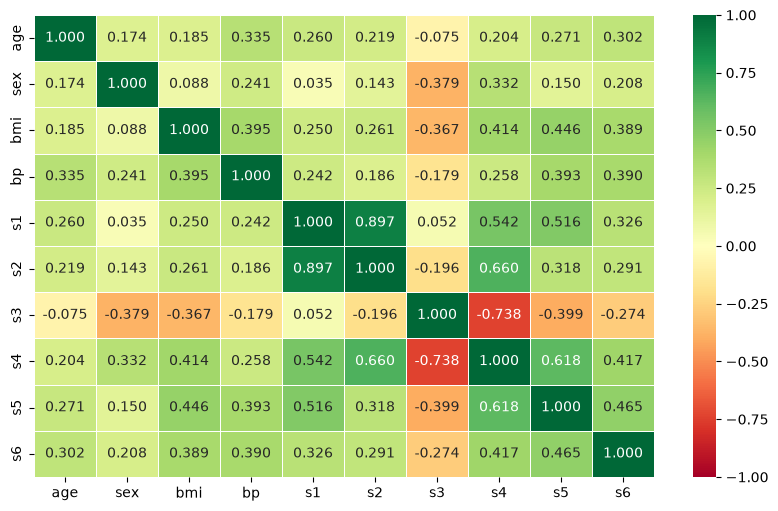

In [5]:
plt.subplots(figsize=(10, 6))

X_corr = X.corr()

sns.heatmap(
            X_corr,
            annot=True,
            fmt=".3f", 
            cmap='RdYlGn', 
            linewidth=.5, 
            vmin=-1, 
            vmax=1
);

In [6]:
# split data to 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### 4.2 Base Model (Linear Regression without Regularization)

In [7]:
# 1. Initialize and fit the scaler on training features only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# 2. Transform the test features using the already-fitted scaler
X_test_scaled = scaler.transform(X_test)

# 3. Initialize, fit, and predict with the Linear Regression model
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)
y_pred = lr.predict(X_test_scaled)

print(f'RMSE: {mean_squared_error(y_test,y_pred)**0.5}')  # complete code here
print(f'R2 Score: {r2_score(y_test,y_pred)}') # or lr.score(X_test_scaled, y_pred)

RMSE: 53.85344583676594
R2 Score: 0.45260276297191915


In [8]:
# Base Model Coefficient 
lr.coef_

array([  1.75375799, -11.51180908,  25.60712144,  16.82887167,
       -44.44885564,  24.64095356,   7.67697768,  13.1387839 ,
        35.16119521,   2.35136365])

In [9]:
# Features with non zero coefficient
(lr.coef_ != 0).sum()

np.int64(10)

In [10]:
# Features with coefficients close to zero
(abs(lr.coef_ )<= 1).sum()

np.int64(0)

### 4.3 Using `RidgeCV` and `LassoCV`

The difference between the standard models (`Ridge` / `Lasso`) and their **"CV"** counterparts (`RidgeCV` / `LassoCV`) comes down to manual vs. automatic **hyperparameter tuning**.

The **"CV" stands for Cross-Validation**. In Scikit-Learn, these CV classes are specially designed to find the **_best penalty strength (the alpha parameter)_** automatically, saving you from having to build a separate `GridSearchCV`.

**Here is the detailed breakdown of how they differ:**
1. **The Standard Models: `Ridge`, `Lasso` and `ElasticNet`**
When you use the standard `Ridge` or `Lasso` classes, **you must guess the penalty strength manually**. You provide a single value for the **alpha** parameter _(e.g., `alpha=1.0`)_. However, in the case of `ElasticNet` you would also need to guess the `l1_ratio` parameter. The model runs once, applies that exact penalty, and finishes. You will need to reiterate the process to find the best alpha manually, or you would have to wrap the model in a `GridSearchCV` and test them all yourself.
2. **The Auto-Tuning Models: `RidgeCV`, `LassoCV`and `ElasticNetCV`**
When you use `RidgeCV` or `LassoCV`, you are handing the model a list of possible penalty strengths (e.g., `alphas=[0.1, 1.0, 10.0]`). The model will automatically test all of them using cross-validation and pick the best one for you. In the case of `ElasticNetCV` you would also need to provide a list of possible `l1_ratio` values.

**RECAP - How the Cross-Validation Works:**
When you call `.fit()`, the model doesn't just evaluate the **alphas** once. It secretly divides your training data into multiple equal chunks (called "folds"). It trains on a few chunks and tests itself on the remaining chunk, rotating through until every piece of data has been used for validation. By averaging the errors across all these folds, it figures out which alpha produces the most consistently accurate results, and then trains its final self using that winning alpha.

>_**This built-in process is highly optimized, computing the best alpha significantly faster than if you used a standard `GridSearchCV`.**_

**Ridge Regression (L2 Regularization)**

In [12]:
# Alpha candidates
np.logspace(-3,3,100) # 100 values between 10^-3 to 10^3

# choosing alpha value is depending  

array([1.00000000e-03, 1.14975700e-03, 1.32194115e-03, 1.51991108e-03,
       1.74752840e-03, 2.00923300e-03, 2.31012970e-03, 2.65608778e-03,
       3.05385551e-03, 3.51119173e-03, 4.03701726e-03, 4.64158883e-03,
       5.33669923e-03, 6.13590727e-03, 7.05480231e-03, 8.11130831e-03,
       9.32603347e-03, 1.07226722e-02, 1.23284674e-02, 1.41747416e-02,
       1.62975083e-02, 1.87381742e-02, 2.15443469e-02, 2.47707636e-02,
       2.84803587e-02, 3.27454916e-02, 3.76493581e-02, 4.32876128e-02,
       4.97702356e-02, 5.72236766e-02, 6.57933225e-02, 7.56463328e-02,
       8.69749003e-02, 1.00000000e-01, 1.14975700e-01, 1.32194115e-01,
       1.51991108e-01, 1.74752840e-01, 2.00923300e-01, 2.31012970e-01,
       2.65608778e-01, 3.05385551e-01, 3.51119173e-01, 4.03701726e-01,
       4.64158883e-01, 5.33669923e-01, 6.13590727e-01, 7.05480231e-01,
       8.11130831e-01, 9.32603347e-01, 1.07226722e+00, 1.23284674e+00,
       1.41747416e+00, 1.62975083e+00, 1.87381742e+00, 2.15443469e+00,
      

In [13]:
from sklearn.linear_model import RidgeCV

# RidgeCV (L2) specify alpha ranges using np.logspace
alphas_val = np.logspace(-3,3,100)

# Cross-validate over our list of ridge alphas.
ridge_cv = RidgeCV(alphas= alphas_val)

# Fit model using best ridge alpha!
ridge_cv.fit(X_train_scaled,y_train)

,"alphas alphas: array-like of shape (n_alphas,), default=(0.1, 1.0, 10.0)Array of alpha values to try.Regularization strength; must be a positive float. Regularizationimproves the conditioning of the problem and reduces the variance ofthe estimates. Larger values specify stronger regularization.Alpha corresponds to ``1 / (2C)`` in other linear models such as:class:`~sklearn.linear_model.LogisticRegression` or:class:`~sklearn.svm.LinearSVC`.If using Leave-One-Out cross-validation, alphas must be strictly positive.For an example on how regularization strength affects the model coefficients,see :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`.",array([1.0000...00000000e+03])
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto false, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"scoring scoring: str, callable, default=NoneThe scoring method to use for cross-validation. Options:- str: see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)``. See :ref:`scoring_callable` for details.- `None`: negative :ref:`mean squared error <mean_squared_error>` if cv is None (i.e. when using leave-one-out cross-validation), or :ref:`coefficient of determination <r2_score>` (:math:`R^2`) otherwise.",None
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the efficient Leave-One-Out cross-validation- integer, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if ``y`` is binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used, else,:class:`~sklearn.model_selection.KFold` is used.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here.",None
,"gcv_mode gcv_mode: {'auto', 'svd', 'eigen'}, default='auto'Flag indicating which strategy to use when performingLeave-One-Out Cross-Validation. Options are:: 'auto' : same as 'eigen' 'svd' : use singular value decomposition of X when X is dense, fallback to 'eigen' when X is sparse 'eigen' : use eigendecomposition of X X' when n_samples <= n_features or X' X when n_features < n_samplesThe 'auto' mode is the default and is intended to pick the cheaperoption depending on the shape and sparsity of the training data.",None
,"store_cv_results store_cv_results: bool, default=FalseFlag indicating if the cross-validation values corresponding toeach alpha should be stored in the ``cv_results_`` attribute (seebelow). This flag is only compatible with ``cv=None`` (i.e. usingLeave-One-Out Cross-Validation)... versionchanged:: 1.5 Parameter name changed from `store_cv_values` to `store_cv_results`.",False
,"alpha_per_target alpha_per_target: bool, default=FalseFlag indicating whether to optimize the alpha value (picked from the`alphas` parameter list) for each target separately (for multi-outputsettings: multiple prediction targets). When set to `True`, afterfitting, the `alpha_` attribute will contain a value for each target.When set to `False`, a single alpha is used for all targets.This flag is only compatible with ``cv=None`` (i.e. usingLeave-One-Out Cross-Validation)... versionadded:: 0.24",False
Name,Type,Value
"alpha_ alpha_: float or ndarray of shape (n_targets,)Estimated regularization parameter, or, if ``alpha_per_target=True``,the estimated regularization parameter for each target.",float,1.233
"best_score_ best_score_: float or ndarray of shape (n_targets,)Score of base estimator with best alpha, or, if``alpha_per_target=True``, a score for each target... versionadded:: 0.23",float64,-3046
"coef_ coef_: ndarray of shape (n_features) or (n_targets, n_features)Weight vector(s).","ndarray[float64](10,)","[ 1.82,-11.43, 25.75,..., 11.53, 30.74, 2.

In [14]:
# Here is the optimal value of alpha
ridge_cv.alpha_

1.232846739442066

In [15]:
# Evaluate the model
y_pred_ridge = ridge_cv.predict(X_test_scaled)

print(f'RMSE: {mean_squared_error(y_test,y_pred_ridge)**0.5}')  # complete code here
print(f'R2 Score: {r2_score(y_test,y_pred_ridge)}') # or lr.score(X_test_scaled, y_pred)

RMSE: 53.76614060233427
R2 Score: 0.4543761650316348


In [16]:
# RidgeCV Coefficients
ridge_cv.coef_

array([  1.81643179, -11.43473133,  25.7499949 ,  16.71618009,
       -33.01917745,  15.77396996,   2.64237036,  11.53019263,
        30.73687911,   2.47841373])

**Lasso Regression (L1 Regularization)**

In [17]:
from sklearn.linear_model import LassoCV

# Set up a list of Lasso alphas to check.
l_alphas = np.logspace(-3,3,100)

# Cross-validate over our list of Lasso alphas.
lasso_cv = LassoCV(alphas= l_alphas)

# Fit model using best ridge alpha!
lasso_cv.fit(X_train_scaled,y_train)

,"alphas alphas: array-like or int, default=100Values of alphas to test along the regularization path.If int, `alphas` values are generated automatically.If array-like, list of alpha values to use... versionchanged:: 1.7 `alphas` accepts an integer value which removes the need to pass `n_alphas`.",array([1.0000...00000000e+03])
,"eps eps: float, default=1e-3Length of the path. ``eps=1e-3`` means that``alpha_min / alpha_max = 1e-3``.",0.001
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto false, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: 'auto', bool or array-like of shape (n_features, n_features), default='auto'Whether to use a precomputed Gram matrix to speed upcalculations. If set to ``'auto'`` let us decide. The Grammatrix can also be passed as an argument.",'auto'
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``.",0.0001
,"copy_X copy_X: bool, default=TrueIf ``True``, `X` will be copied; otherwise, it may be overwritten.",True
,"cv cv: int, cross-validation generator or iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- int, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For int/None inputs, :class:`~sklearn.model_selection.KFold` is used.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"verbose verbose: bool or int, default=FalseAmount of verbosity.",False
,"n_jobs n_jobs: int, default=NoneNumber of CPUs to use during the cross validation.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"positive positive: bool, default=FalseIf positive, restrict regression coefficients to be positive.",False


In [19]:
# Here is the optimal value of alpha
lasso_cv.alpha_

np.float64(1.629750834620645)

In [20]:
# Evaluate the model
y_pred_lasso = lasso_cv.predict(X_test_scaled)

print(f'RMSE: {mean_squared_error(y_test,y_pred_lasso)**0.5}')  # complete code here
print(f'R2 Score: {r2_score(y_test,y_pred_lasso)}') # or lr.score(X_test_scaled, y_pred)

RMSE: 52.92133838246166
R2 Score: 0.47138772365756554


In [21]:
# LassoCV Coefficient 
lasso_cv.coef_

array([  0.        ,  -8.02142643,  26.18903241,  15.06441946,
        -4.86012346,  -0.        , -11.08667637,   0.        ,
        21.99612869,   1.75881184])

**ElasticNet (The Hybrid)**

ElasticNet combines both the **Lasso (L1)** and **Ridge (L2)** penalties into a single equation.
- It uses a hyperparameter (often called the `l1_ratio`__*__) to balance the behavior of Ridge and Lasso.
- Situations where you have a massive dataset with lots of correlated features, and you want the feature selection of Lasso without it randomly dropping correlated features too aggressively.
- It is the safest "best of both worlds" approach, but it requires more computational time to tune both the overall penalty strength and the L1/L2 ratio.

>__*__ The `l1_ratio` is a number that must fall strictly between 0.0 and 1.0. Here is how to think about the values:
>- __`l1_ratio = 0.0` (Pure Ridge):__ The model completely ignores the Lasso penalty. (Note: Scikit-Learn actually recommends just using the Ridge class if you want this, as it calculates faster!)
>- __`l1_ratio = 1.0` (Pure Lasso):__ The model completely ignores the Ridge penalty.
>- __`l1_ratio = 0.5` (50/50 Split):__ The model applies an equal mathematical penalty from both L1 and L2.

>By setting the l1_ratio to something high like 0.95, you are telling the model: __*"Act 95% like Lasso and drop the useless columns, but keep 5% of Ridge's behavior just to act as 'glue' to stabilize the highly correlated features."*__

In [22]:
from sklearn.linear_model import ElasticNetCV

#  Define parameter grids for ElasticNetCV
alphas_val = np.logspace(-5, 5, 100)
l1_ratio_val = np.linspace(0.1,1,10)

# Cross-validate over our list of Lasso alphas.
elastic_cv = ElasticNetCV(
                    alphas = l_alphas, 
                    l1_ratio = l1_ratio_val,
                    cv=5
                    )

# Fit model using best ridge alpha!
elastic_cv.fit(X_train_scaled, y_train)

,"l1_ratio l1_ratio: float or list of float, default=0.5Float between 0 and 1 passed to ElasticNet (scaling betweenl1 and l2 penalties). For ``l1_ratio = 0``the penalty is an L2 penalty. For ``l1_ratio = 1`` it is an L1 penalty.For ``0 < l1_ratio < 1``, the penalty is a combination of L1 and L2This parameter can be a list, in which case the differentvalues are tested by cross-validation and the one giving the bestprediction score is used. Note that a good choice of list ofvalues for l1_ratio is often to put more values close to 1(i.e. Lasso) and less close to 0 (i.e. Ridge), as in ``[.1, .5, .7,.9, .95, .99, 1]``.","array([0.1, 0....8, 0.9, 1. ])"
,"alphas alphas: array-like or int, default=100Values of alphas to test along the regularization path, used for each l1_ratio.If int, `alphas` values are generated automatically.If array-like, list of alpha values to use... versionchanged:: 1.7 `alphas` accepts an integer value which removes the need to pass `n_alphas`.",array([1.0000...00000000e+03])
,"cv cv: int, cross-validation generator or iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- int, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For int/None inputs, :class:`~sklearn.model_selection.KFold` is used.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"eps eps: float, default=1e-3Length of the path. ``eps=1e-3`` means that``alpha_min / alpha_max = 1e-3``.",0.001
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto false, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: 'auto', bool or array-like of shape (n_features, n_features), default='auto'Whether to use a precomputed Gram matrix to speed upcalculations. If set to ``'auto'`` let us decide. The Grammatrix can also be passed as argument.",'auto'
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``.",0.0001
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"verbose verbose: bool or int, default=0Amount of verbosity.",0
,"n_jobs n_jobs: int, default=NoneNumber of CPUs to use during the cross validation.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None


In [23]:
# Here is the optimal value of alpha
elastic_cv.alpha_

np.float64(0.11497569953977356)

In [24]:
# Here is the optimal value of l1_ratio
elastic_cv.l1_ratio_

np.float64(0.1)

In [26]:
elastic_cv.coef_

array([  1.98738443, -10.0053594 ,  24.29109306,  15.46515231,
        -5.70802577,  -3.91621575,  -8.88148158,   7.26660209,
        19.15924223,   3.67349516])

In [25]:
# Evaluate the model
y_pred_elastic = elastic_cv.predict(X_test_scaled)

print(f'RMSE: {mean_squared_error(y_test,y_pred_elastic)**0.5}')  # complete code here
print(f'R2 Score: {r2_score(y_test,y_pred_elastic)}') # or lr.score(X_test_scaled, y_pred)

RMSE: 53.469101976652006
R2 Score: 0.4603882633240789


**Regulariztion with Logistic Regression**

With logistic regression, regularization is built directly into `LogisticRegression`.

The main difference from Ridge/Lasso regression is that logistic regression uses `C`, where:
- Smaller `C` = stronger regularization
- Larger `C` = weaker regularization

In [27]:
# Data Creation
from sklearn.datasets import make_classification

X, y = make_classification(
    n_samples=1000,
    n_features=200,
    n_informative=15,
    random_state=123
)

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=123)

sc = StandardScaler()
X_train_sc = sc.fit_transform(X_train)
X_test_sc = sc.transform(X_test)

In [28]:
y_train[:10]

array([1, 1, 0, 0, 0, 1, 0, 1, 0, 0])

In [ ]:
from sklearn.linear_model import LogisticRegression

# L2 regularization (Ridge-like)
lr_l2 = LogisticRegression(
                penalty='l2',
                C=1.0, # acts like alpha in LR regularization
)

lr_l2.fit(X_train_sc, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'l2'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects

In [30]:
# L1 regularization (Lasso-like)
lr_l1 = LogisticRegression(
                penalty='l1',
                C=1.0, # acts like alpha in LR regularization
                solver='liblinear'
)

lr_l1.fit(X_train_sc, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'l1'
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, 

In [31]:
# Elastic
lr_en = LogisticRegression(
    penalty = 'elasticnet',
    C = 1.0,
    l1_ratio = 0.5,
    solver = "saga"
)

lr_en.fit(X_train_sc, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'elasticnet'
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.5
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'saga'
,"C C: float, default=1.0Inverse of regularization str

In [ ]:
# L2 regularization (Ridge-like) with cross validate

from sklearn.linear_model import ________


C_values = np.logspace(-3, 3, 100)

lr_cv = ________(
    ________=________,
    ________=________,
    ________=________,
    ________=________
)

lr_cv.fit(X_train_sc, y_train)

## Wrap-Up:

It is completely normal to feel overwhelmed by all these different models and acronyms! The most important thing to remember as a data scientist is this: **You do not need to magically know the perfect model before you start.** Machine learning is about conducting controlled experiments. You start with a simple baseline model. If it overfits, you run a new experiment adding a "penalty" (regularization). You observe the results, tweak the approach, and see what works best for your specific data.

Here is your conceptual guide for setting up those experiments.

### The "Which Approach Do I Choose?" Guide

When deciding which regularization experiment to run, think about what you want to do with your dataset's columns (features):

* **Ridge (L2):** Choose this when you believe all features contribute a small, real effect to the prediction, or when features are highly correlated. Instead of throwing columns away, Ridge evenly shrinks all coefficient weights to stabilize the model and combat multicollinearity. It serves as your safest, most reliable baseline experiment.
* **Lasso (L1):** Choose this when you have a high-dimensional dataset (many columns) and suspect a significant portion of them are irrelevant noise. Lasso acts as a built-in feature selector—its absolute penalty geometry ruthlessly forces the weights of non-predictive variables to exactly zero, generating a clean, highly interpretable sparse model (most of the coefficient weights are set exactly to zero)
* **ElasticNet:** Choose this when you are dealing with a complex, high-dimensional dataset containing many highly correlated features. ElasticNet combines the strengths of both worlds—it leverages Lasso (L1) to ruthlessly eliminate completely useless noise, while utilizing Ridge (L2) to ensure that correlated variables share weight and stabilize the model rather than being arbitrarily deleted.

### Watch Out For:

No matter which experiment you run, if you forget these three rules, your results will be invalid:

1. **You Must Scale Your Data:** Regularization is obsessed with the size of your numbers. If you do not put your data through a `StandardScaler`, a column with large numbers (like Income = $80,000) will be penalized much harder than a column with small numbers (like Age = 25).
3. **Opposite Dials (`alpha` vs. `C`):**
    * When running **Regression** (Ridge/Lasso), the penalty dial is called **`alpha`**. Turning it *up* makes the penalty stronger.
    * When running **Classification** (Logistic Regression), the penalty dial is called **`C`**. Turning it *down* makes the penalty stronger.